# EcoPulse AI - Phase 4

## 1. Project Introduction

**Project:** EcoPulse AI - Intelligent Energy Consumption Monitoring,
Forecasting and Anomaly Detection System

**Notebook:** `04_anomaly_detection.ipynb`

This notebook documents the unsupervised anomaly-detection experiment on the
Phase 3 cleaned minute-level data. It loads the saved detection outputs, the
fitted Isolation Forest, the persisted scaler and the real report artefacts.

**There are no reliable ground-truth anomaly labels.** Accuracy, precision,
recall and F1 are therefore not calculated. Detected observations are
*deviation candidates* for investigation, not confirmed faults.

## 2. Objectives

1. Verify the cleaned-minute exclusions and chronological splits.
2. Explain the two complementary unsupervised methods.
3. Quantify detection volume overall and by split.
4. Compare method agreement without calling it accuracy.
5. Reload the scaler and Isolation Forest and reproduce stored test flags.
6. Present the real figures generated by the evaluation stage.

The z-score baseline uses one variable and a fixed threshold. The Isolation
Forest uses 20 measurement, calendar and historical features with a prior
contamination setting of 0.5%.

## 3. Import Libraries and Locate the Project

The notebook discovers the repository root by walking up from the current
working directory, so it runs both from the project root and from
`data-engineering/notebooks/`. It imports the same feature constants and metric
functions used by the pipeline instead of redefining them.

In [1]:
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)


def find_project_root() -> Path:
    """Find the EcoPulse AI root from the notebook working directory."""
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / "machine-learning" / "utils" / "features.py").is_file()
            and (candidate / "reports" / "machine-learning").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the EcoPulse AI repository. "
        "Open this notebook from inside the project."
    )


def sha256sum(path: Path) -> str:
    """Return the SHA-256 digest of a file."""
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


PROJECT_ROOT = find_project_root()
MACHINE_LEARNING_DIR = PROJECT_ROOT / "machine-learning"
if str(MACHINE_LEARNING_DIR) not in sys.path:
    sys.path.insert(0, str(MACHINE_LEARNING_DIR))

from utils.features import ANOMALY_FEATURES  # noqa: E402

DATA_DIR = PROJECT_ROOT / "data" / "processed" / "ml"
MODEL_DIR = MACHINE_LEARNING_DIR / "models" / "forecasting"
REPORT_DIR = PROJECT_ROOT / "reports" / "machine-learning"
FIGURE_DIR = REPORT_DIR / "figures"

print(f"Project root: {PROJECT_ROOT}")
print(f"Anomaly features: {len(ANOMALY_FEATURES)}")
print(f"pandas {pd.__version__} | numpy {np.__version__}")

Project root: D:\ai\EcoPulse-AI
Anomaly features: 20
pandas 2.3.3 | numpy 2.5.5


## 4. Configuration and Required Artefacts

The notebook stops if any saved output is missing. It never refits the models
and never fabricates labels.

In [2]:
ANOMALY_DATA_PATH = DATA_DIR / "anomaly_dataset.parquet"
PREDICTIONS_PATH = DATA_DIR / "anomaly_predictions.parquet"
TRAINING_SUMMARY_PATH = DATA_DIR / "anomaly_training_summary.json"
SUMMARY_CSV_PATH = REPORT_DIR / "anomaly_summary.csv"
REPORT_PATH = REPORT_DIR / "anomaly_detection_report.txt"
MODEL_PATH = MACHINE_LEARNING_DIR / "models" / "anomaly_detection" / "isolation_forest.joblib"
SCALER_PATH = MACHINE_LEARNING_DIR / "models" / "anomaly_detection" / "anomaly_scaler.joblib"
METADATA_PATH = MACHINE_LEARNING_DIR / "models" / "anomaly_detection" / "anomaly_metadata.json"
FEATURES_PATH = MACHINE_LEARNING_DIR / "models" / "anomaly_detection" / "anomaly_features.json"

required_paths = {
    "prepared anomaly dataset": ANOMALY_DATA_PATH,
    "saved predictions": PREDICTIONS_PATH,
    "training summary": TRAINING_SUMMARY_PATH,
    "summary CSV": SUMMARY_CSV_PATH,
    "anomaly report": REPORT_PATH,
    "Isolation Forest": MODEL_PATH,
    "scaler": SCALER_PATH,
    "metadata": METADATA_PATH,
    "feature list": FEATURES_PATH,
}
missing = [name for name, path in required_paths.items() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Missing Phase 4 anomaly outputs: " + ", ".join(missing)
        + ". Run machine-learning/src/06_run_ml_pipeline.py first."
    )

predictions = pd.read_parquet(PREDICTIONS_PATH)
training_summary = json.loads(TRAINING_SUMMARY_PATH.read_text(encoding="utf-8"))
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
feature_document = json.loads(FEATURES_PATH.read_text(encoding="utf-8"))
counts = pd.read_csv(SUMMARY_CSV_PATH)

print(f"Scored minutes:          {len(predictions):,}")
print(f"Features:                {len(feature_document['features'])}")
print(f"Contamination prior:     {metadata['contamination']:.2%}")
print(f"Z-score threshold:       |z| >= {metadata['zscore_baseline']['threshold']}")
print(f"IF decision threshold:   {metadata['isolation_forest']['decision_threshold']}")
print(f"IF raw-score offset:     {metadata['isolation_forest']['iforest_offset']:.6f}")

Scored minutes:          2,043,373
Features:                20
Contamination prior:     0.50%
Z-score threshold:       |z| >= 3.0
IF decision threshold:   0.0
IF raw-score offset:     -0.667777


## 5. Dataset, Exclusions and Splits

Interpolated minutes are excluded from anomaly modelling because they were not
observed. Rows without a full prior 24-hour baseline are also excluded. The
remaining minutes are split chronologically into train, validation and test.

In [3]:
source = metadata["source"]
overview = pd.DataFrame(
    {
        "value": [
            f"{source['cleaned_minutes']:,}",
            f"{source['imputed_rows_excluded']:,}",
            f"{source['warmup_or_gap_rows_excluded']:,}",
            f"{source['usable_minutes']:,}",
        ]
    },
    index=[
        "Cleaned minute observations",
        "Imputed rows excluded",
        "Warm-up / short-gap rows excluded",
        "Usable scored minutes",
    ],
)
display(overview)

split_rows = []
for split in ("train", "validation", "test"):
    period = metadata["training_period" if split == "train" else f"{split}_period"]
    split_rows.append(
        {
            "split": split,
            "rows": period["rows"],
            "start": period["start"][:19],
            "end": period["end"][:19],
        }
    )
split_table = pd.DataFrame(split_rows).set_index("split")
split_table["rows"] = split_table["rows"].map("{:,}".format)
display(split_table)

assert len(predictions) == training_summary["rows"] == source["usable_minutes"]
assert predictions["timestamp"].is_monotonic_increasing
assert not predictions["timestamp"].duplicated().any()
assert int(counts["total_observations"].max()) == len(predictions)
print("Prediction rows and timestamps reconcile with the training summary.")

,value
Cleaned minute observations,"2,049,356"
Imputed rows excluded,76
Warm-up / short-gap rows excluded,"5,983"
Usable scored minutes,"2,043,373"


,rows,start,end
split,,,
train,"1,430,361",2006-12-17T05:24:00,2009-09-12T22:18:00
validation,"306,505",2009-09-12T22:19:00,2010-04-18T08:49:00
test,"306,507",2010-04-18T08:50:00,2010-11-26T21:02:00


Prediction rows and timestamps reconcile with the training summary.


## 6. Detection Methods

**A. Causal rolling z-score baseline**

For each minute, the previous 24-hour mean and standard deviation of
`Global_active_power` are computed after shifting by one minute. A minute is
flagged when `|z| >= 3.0`. The current reading is never part of its own baseline.

**B. Isolation Forest**

A StandardScaler and an Isolation Forest with 200 trees, `max_samples=256`, a
fixed random seed and `contamination=0.005` are fitted on the training split
only. The decision threshold is `0.0`; the stored `offset_` shifts raw scores
into that decision function. The 0.5% contamination is a prior assumption, not
an estimated fault prevalence.

## 7. Detection Volume

These counts are loaded from `anomaly_summary.csv`, which is recomputed from the
prediction table during evaluation. The in-sample Isolation Forest rate on train
is not directly comparable with validation/test rates.

In [4]:
overall_table = counts[
    ["detection_method", "total_observations", "detected_anomalies", "anomaly_percentage"]
].copy()
display(
    overall_table.style.format(
        {
            "total_observations": "{:,}",
            "detected_anomalies": "{:,}",
            "anomaly_percentage": "{:.3f}%",
        }
    ).set_caption("Overall detection volume")
)

split_table = counts[
    [
        "detection_method",
        "train_anomalies",
        "train_anomaly_percentage",
        "validation_anomalies",
        "validation_anomaly_percentage",
        "test_anomalies",
        "test_anomaly_percentage",
    ]
].copy()
display(
    split_table.style.format(
        {
            "train_anomalies": "{:,}",
            "train_anomaly_percentage": "{:.3f}%",
            "validation_anomalies": "{:,}",
            "validation_anomaly_percentage": "{:.3f}%",
            "test_anomalies": "{:,}",
            "test_anomaly_percentage": "{:.3f}%",
        }
    ).set_caption("Detected minutes by chronological split")
)
print("The train rate is in-sample; validation and test reflect unseen minutes.")

,detection_method,total_observations,detected_anomalies,anomaly_percentage
0,Rolling z-score (|z| >= 3.0),"2,043,373","45,325",2.218%
1,Isolation Forest (contamination=0.005),"2,043,373","8,809",0.431%


,detection_method,train_anomalies,train_anomaly_percentage,validation_anomalies,validation_anomaly_percentage,test_anomalies,test_anomaly_percentage
0,Rolling z-score (|z| >= 3.0),"33,693",2.356%,"5,863",1.913%,"5,769",1.882%
1,Isolation Forest (contamination=0.005),"7,152",0.500%,"1,286",0.420%,371,0.121%


The train rate is in-sample; validation and test reflect unseen minutes.


## 8. Method Agreement, Not Accuracy

Agreement is descriptive. It is not precision or recall because no labels exist.

In [5]:
iforest = predictions["isolation_forest_anomaly"].astype(bool)
zscore = predictions["zscore_anomaly"].astype(bool)
agreement = pd.crosstab(
    pd.Series(iforest, name="Isolation Forest"),
    pd.Series(zscore, name="Rolling z-score"),
)
agreement.index = agreement.index.map({False: "Normal", True: "Flagged"})
agreement.columns = agreement.columns.map({False: "Normal", True: "Flagged"})
agreement.index.name = "Isolation Forest"
agreement.columns.name = "Rolling z-score"
display(agreement)

both = int((iforest & zscore).sum())
only_iforest = int((iforest & ~zscore).sum())
only_zscore = int((~iforest & zscore).sum())
neither = int((~iforest & ~zscore).sum())
union = both + only_iforest + only_zscore
jaccard = both / union * 100.0 if union else 0.0
correlation = float(
    predictions[["isolation_forest_score", "gap_z_24h"]].corr().iloc[0, 1]
)

print(f"Flagged by both:                 {both:,}")
print(f"Flagged by Isolation Forest only: {only_iforest:,}")
print(f"Flagged by rolling z-score only:  {only_zscore:,}")
print(f"Flagged by neither:              {neither:,}")
print(f"Jaccard overlap:                 {jaccard:.2f}%")
print(f"Pearson correlation (IF score vs z-score): {correlation:.4f}")
print("Agreement is not accuracy; a shared flag can still be a false alarm.")

Rolling z-score,Normal,Flagged
Isolation Forest,,
Normal,1995530,39034
Flagged,2518,6291


Flagged by both:                 6,291
Flagged by Isolation Forest only: 2,518
Flagged by rolling z-score only:  39,034
Flagged by neither:              1,995,530
Jaccard overlap:                 13.15%
Pearson correlation (IF score vs z-score): -0.7440
Agreement is not accuracy; a shared flag can still be a false alarm.


## 9. Extreme Scored Observations

The most extreme minutes are shown as investigation candidates. A high reading
can be normal behaviour, and a genuine fault can produce an unremarkable value.

In [6]:
display_columns = [
    "timestamp",
    "split",
    "Global_active_power",
    "Voltage",
    "gap_z_24h",
    "isolation_forest_score",
]
top_iforest = predictions.nsmallest(8, "isolation_forest_score")[
    display_columns
].copy()
display(
    top_iforest.style.format(
        {
            "Global_active_power": "{:.3f}",
            "Voltage": "{:.2f}",
            "gap_z_24h": "{:.3f}",
            "isolation_forest_score": "{:.4f}",
        }
    ).set_caption("Lowest Isolation Forest decision scores")
)

top_zscore = (
    predictions.assign(abs_z=predictions["gap_z_24h"].abs())
    .nlargest(8, "abs_z")[display_columns + ["abs_z"]]
    .copy()
)
display(
    top_zscore.style.format(
        {
            "Global_active_power": "{:.3f}",
            "Voltage": "{:.2f}",
            "gap_z_24h": "{:.3f}",
            "isolation_forest_score": "{:.4f}",
            "abs_z": "{:.3f}",
        }
    ).set_caption("Largest absolute rolling z-scores")
)

,timestamp,split,Global_active_power,Voltage,gap_z_24h,isolation_forest_score
530368,2007-12-23 19:33:00,train,8.288,232.45,3.908,-0.0785
530367,2007-12-23 19:32:00,train,8.262,233.12,3.915,-0.0782
530366,2007-12-23 19:31:00,train,8.186,232.26,3.892,-0.0780
530369,2007-12-23 19:34:00,train,8.634,231.96,4.094,-0.0752
69953,2007-02-03 19:23:00,train,7.848,229.23,3.905,-0.0747
69954,2007-02-03 19:24:00,train,7.820,229.23,3.861,-0.0747
69959,2007-02-03 19:29:00,train,7.800,228.89,3.779,-0.0727
962712,2008-10-19 01:29:00,train,8.702,229.65,3.859,-0.0721


,timestamp,split,Global_active_power,Voltage,gap_z_24h,isolation_forest_score,abs_z
452255,2007-10-30 13:37:00,train,7.836,231.72,14.397,-0.0271,14.397
714147,2008-04-29 10:37:00,train,4.946,232.71,13.677,-0.0079,13.677
452256,2007-10-30 13:38:00,train,7.920,232.17,13.605,-0.0382,13.605
892924,2008-08-31 14:20:00,train,2.656,235.22,13.435,0.0753,13.435
1365145,2009-07-28 12:33:00,train,5.340,236.70,13.339,-0.0024,13.339
714151,2008-04-29 10:41:00,train,5.878,231.20,13.276,-0.0267,13.276
714156,2008-04-29 10:46:00,train,7.222,231.46,12.993,-0.0501,12.993
1365144,2009-07-28 12:32:00,train,4.934,237.16,12.932,0.0179,12.932


## 10. Saved-Model Reload Verification

A fixed random sample of 25,000 test minutes is scored after reloading the saved
scaler and forest. The reproduced flags are compared with the stored flags. The
z-score flags are also recomputed from the stored causal z-scores.

In [7]:
test_predictions = (
    predictions.loc[predictions["split"] == "test"]
    .sort_values("timestamp")
    .reset_index(drop=True)
)
sample = test_predictions.sample(
    n=min(25_000, len(test_predictions)), random_state=42
).sort_values("timestamp")

feature_source = pd.read_parquet(
    ANOMALY_DATA_PATH,
    columns=["timestamp", *feature_document["features"]],
    filters=[("split", "==", "test")],
).set_index("timestamp")
features = feature_source.loc[sample["timestamp"], feature_document["features"]].to_numpy(
    dtype=np.float64
)

scaler = joblib.load(SCALER_PATH)
bundle = joblib.load(MODEL_PATH)
scaled = scaler.transform(features)
reloaded_flags = bundle["model"].predict(scaled) == -1
stored_flags = sample["isolation_forest_anomaly"].astype(bool).to_numpy()
iforest_mismatches = int(np.count_nonzero(reloaded_flags != stored_flags))

z_threshold = float(metadata["zscore_baseline"]["threshold"])
z_flags = np.abs(sample["gap_z_24h"].to_numpy(dtype=float)) >= z_threshold
stored_z = sample["zscore_anomaly"].astype(bool).to_numpy()
z_mismatches = int(np.count_nonzero(z_flags != stored_z))

print(f"Test minutes available:       {len(test_predictions):,}")
print(f"Sample scored after reload:   {len(sample):,}")
print(f"Isolation Forest mismatches:  {iforest_mismatches:,}")
print(f"Z-score mismatches:           {z_mismatches:,}")
print(
    f"Stored IF offset:             {bundle['threshold']:.9f} | "
    f"metadata {metadata['isolation_forest']['iforest_offset']:.9f}"
)
assert iforest_mismatches == 0
assert z_mismatches == 0
assert abs(float(bundle["threshold"]) - float(metadata["isolation_forest"]["iforest_offset"])) <= 1e-12
print("Reloaded artefacts reproduce every stored flag in the sample.")

Test minutes available:       306,507
Sample scored after reload:   25,000
Isolation Forest mismatches:  0
Z-score mismatches:           0
Stored IF offset:             -0.667776688 | metadata -0.667776688
Reloaded artefacts reproduce every stored flag in the sample.


## 11. Real Detection Figures

The six figures below were generated by `05_evaluate_anomaly_detection.py` from
the scored observations.

**anomaly_consumption_timeline.png**

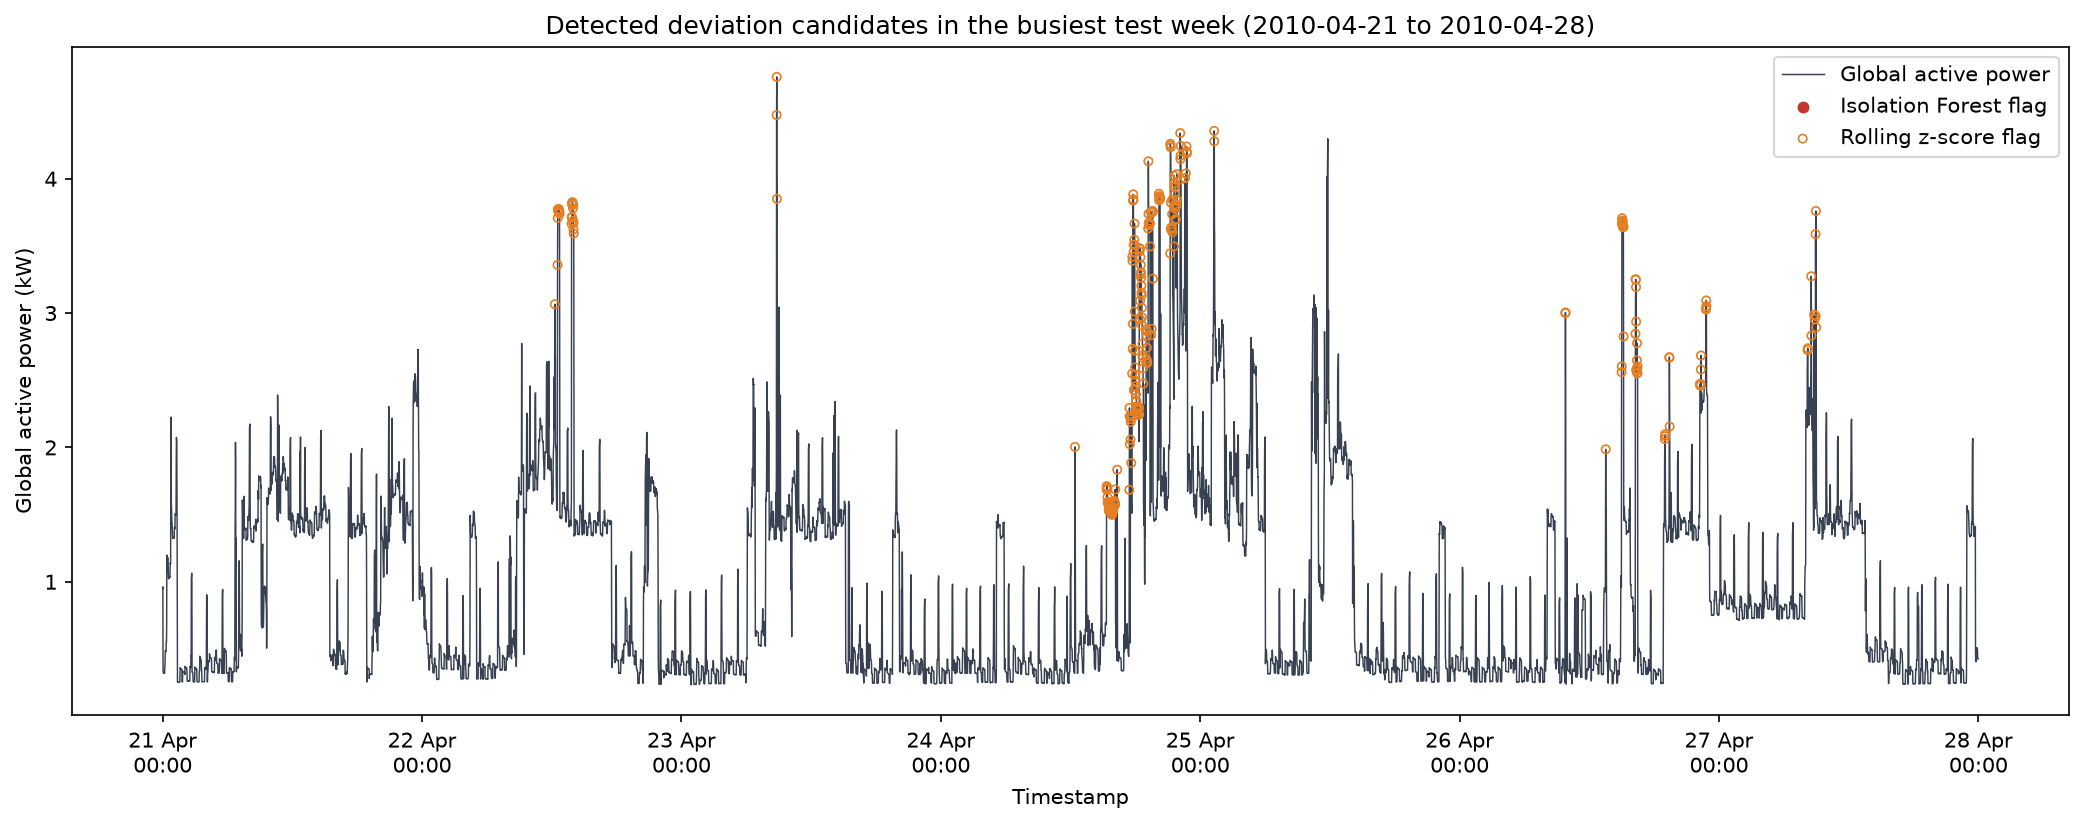

**anomaly_distribution_over_time.png**

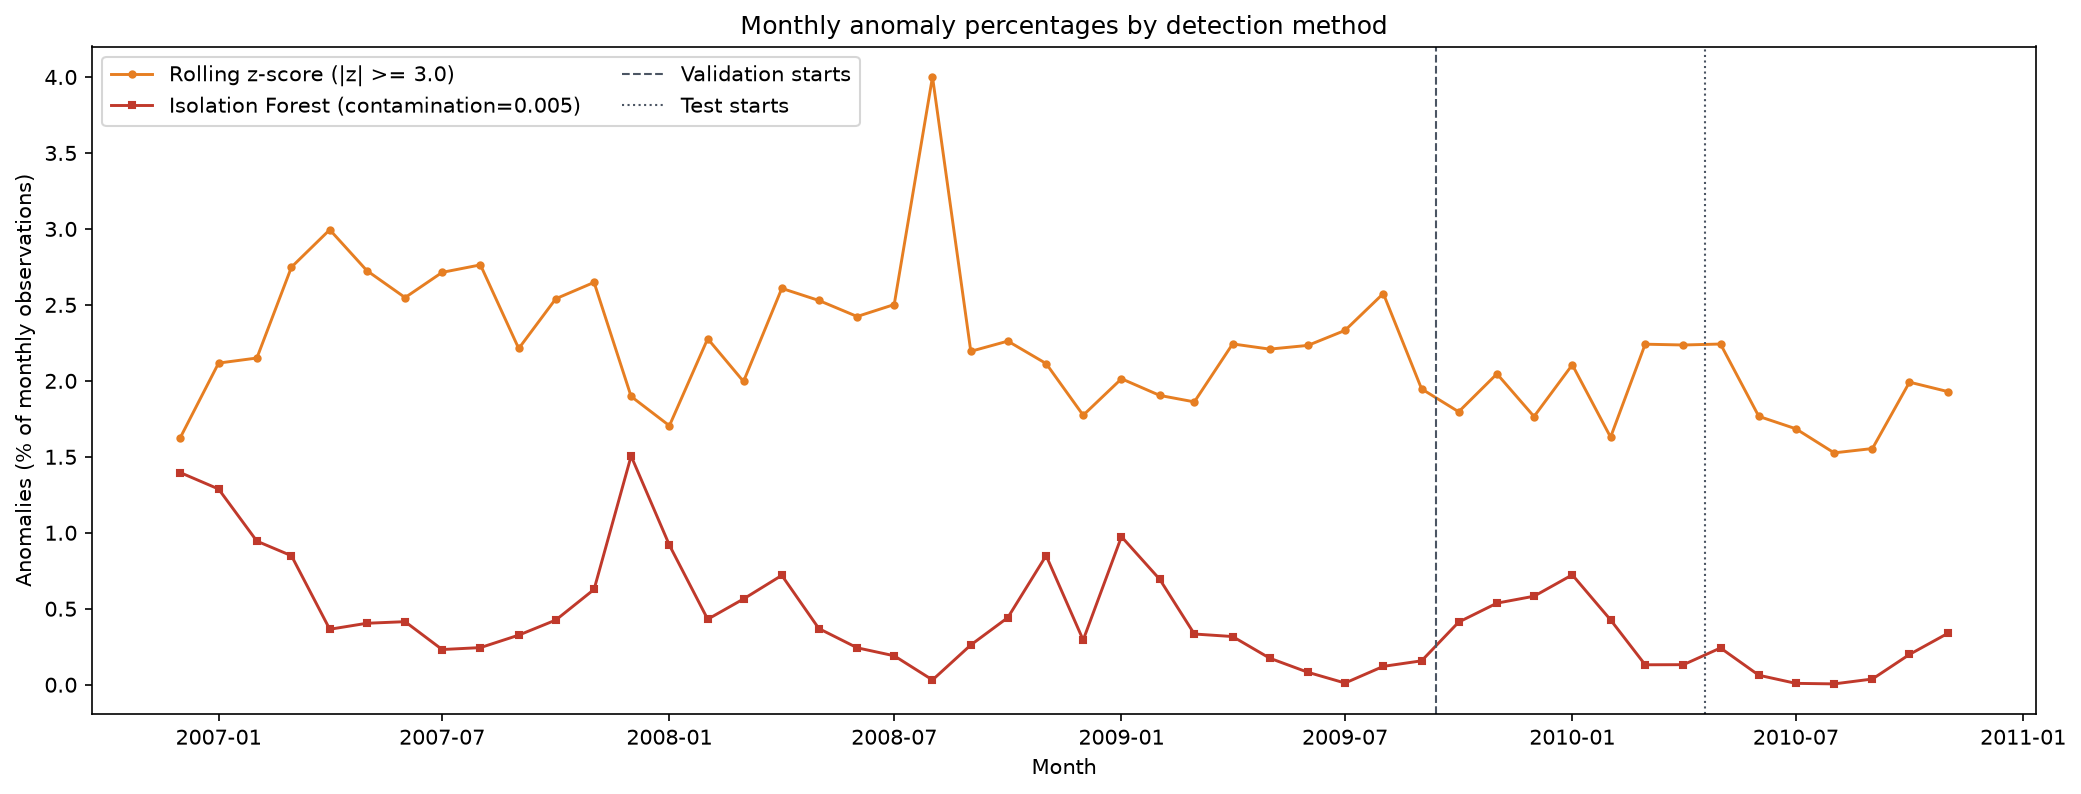

**anomaly_score_distribution.png**

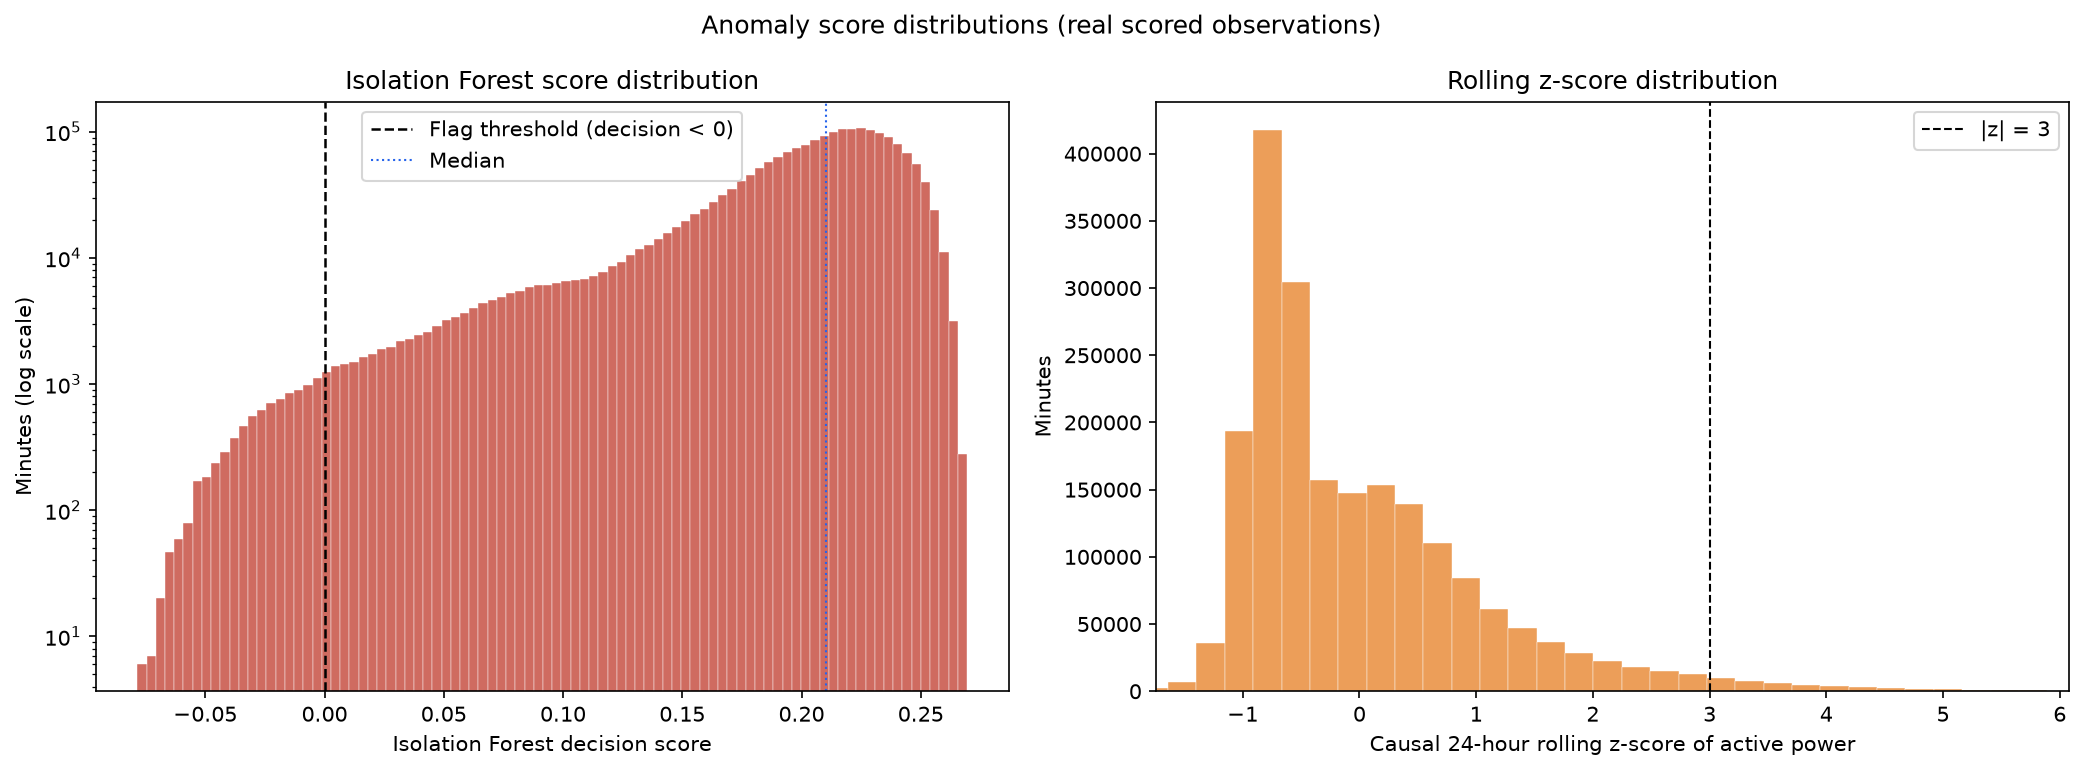

**anomaly_method_comparison.png**

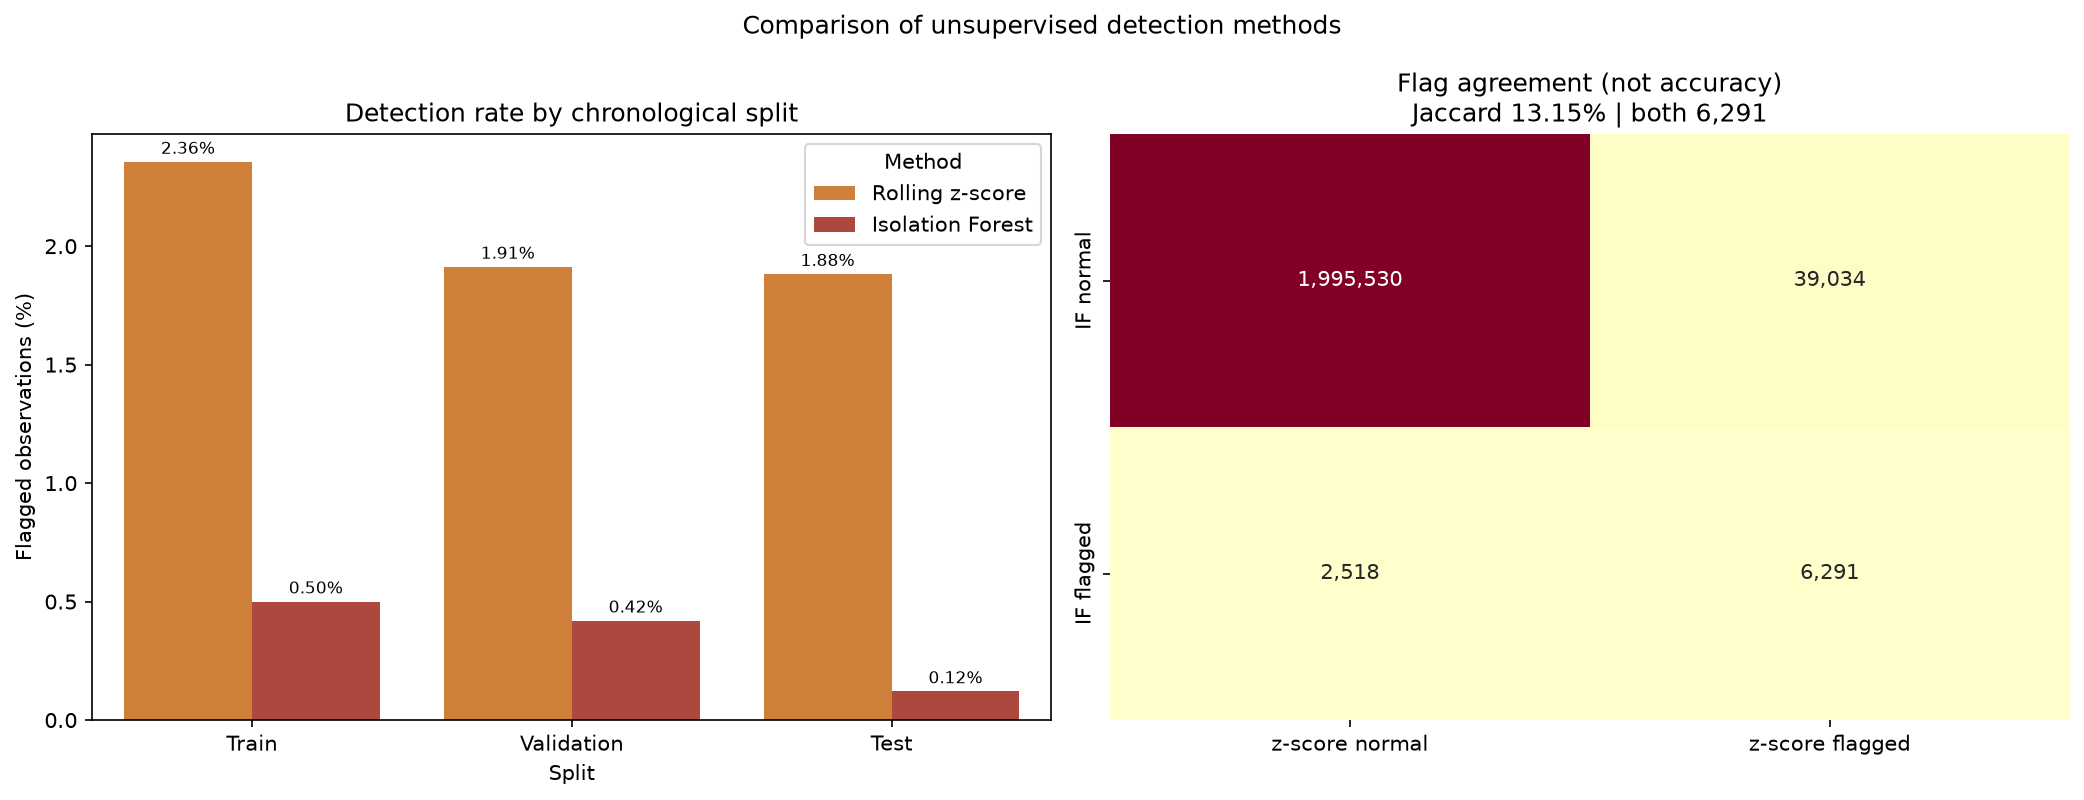

**anomaly_hourly_profile.png**

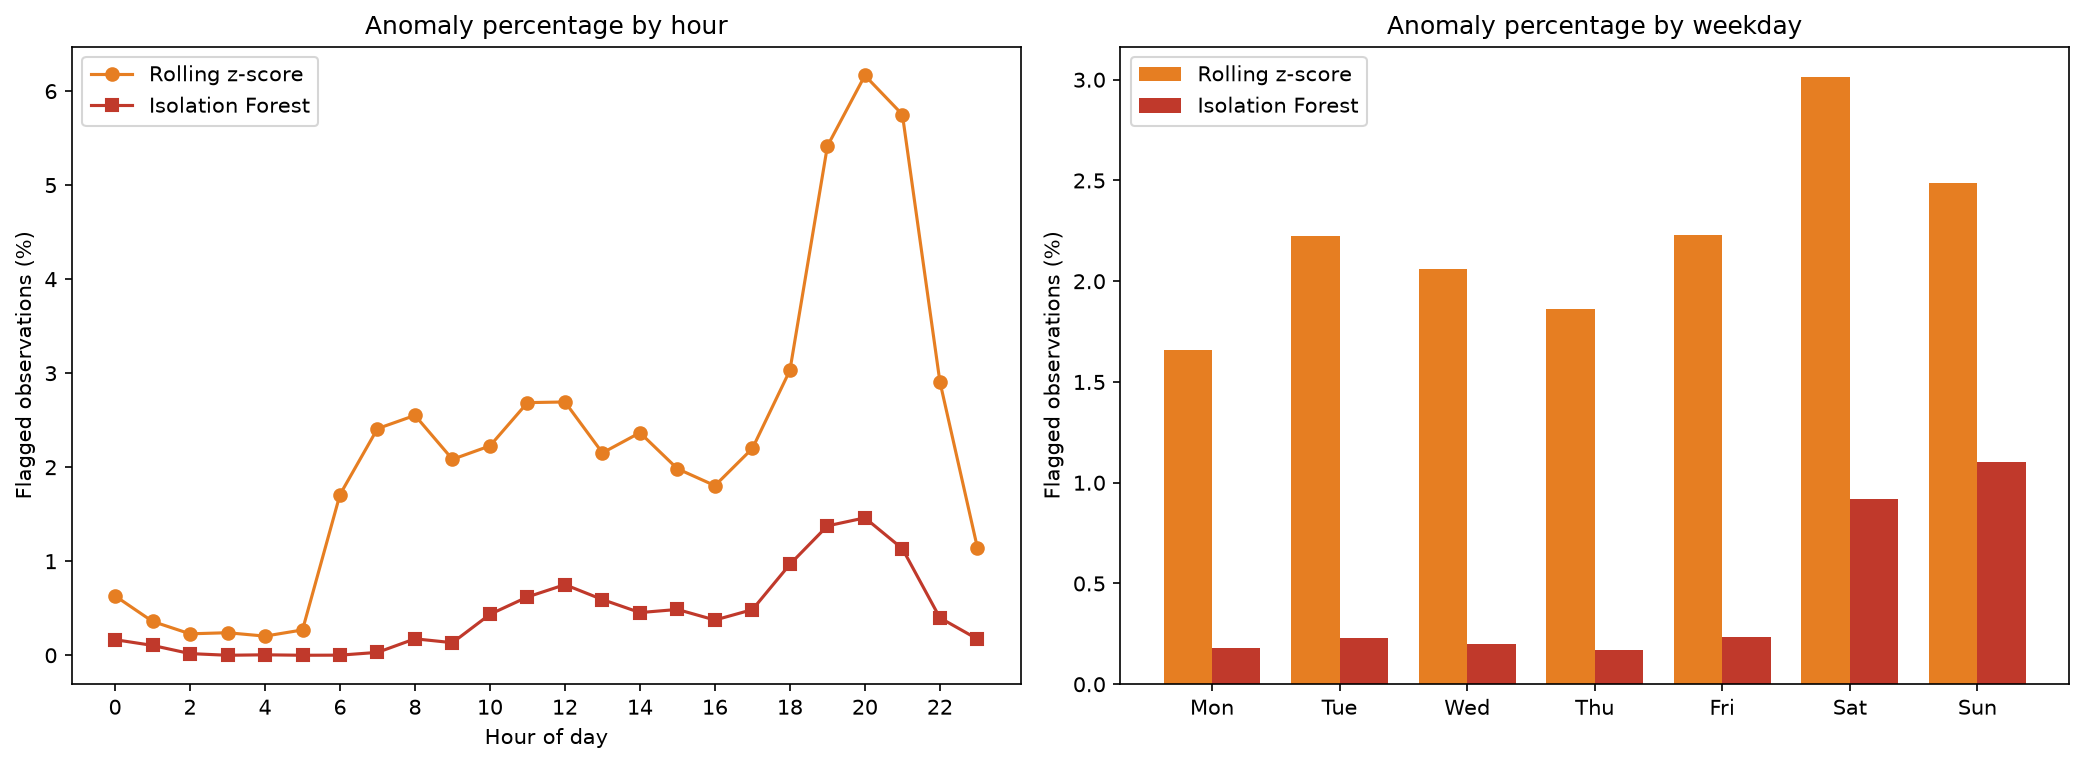

**anomaly_normal_vs_anomalous.png**

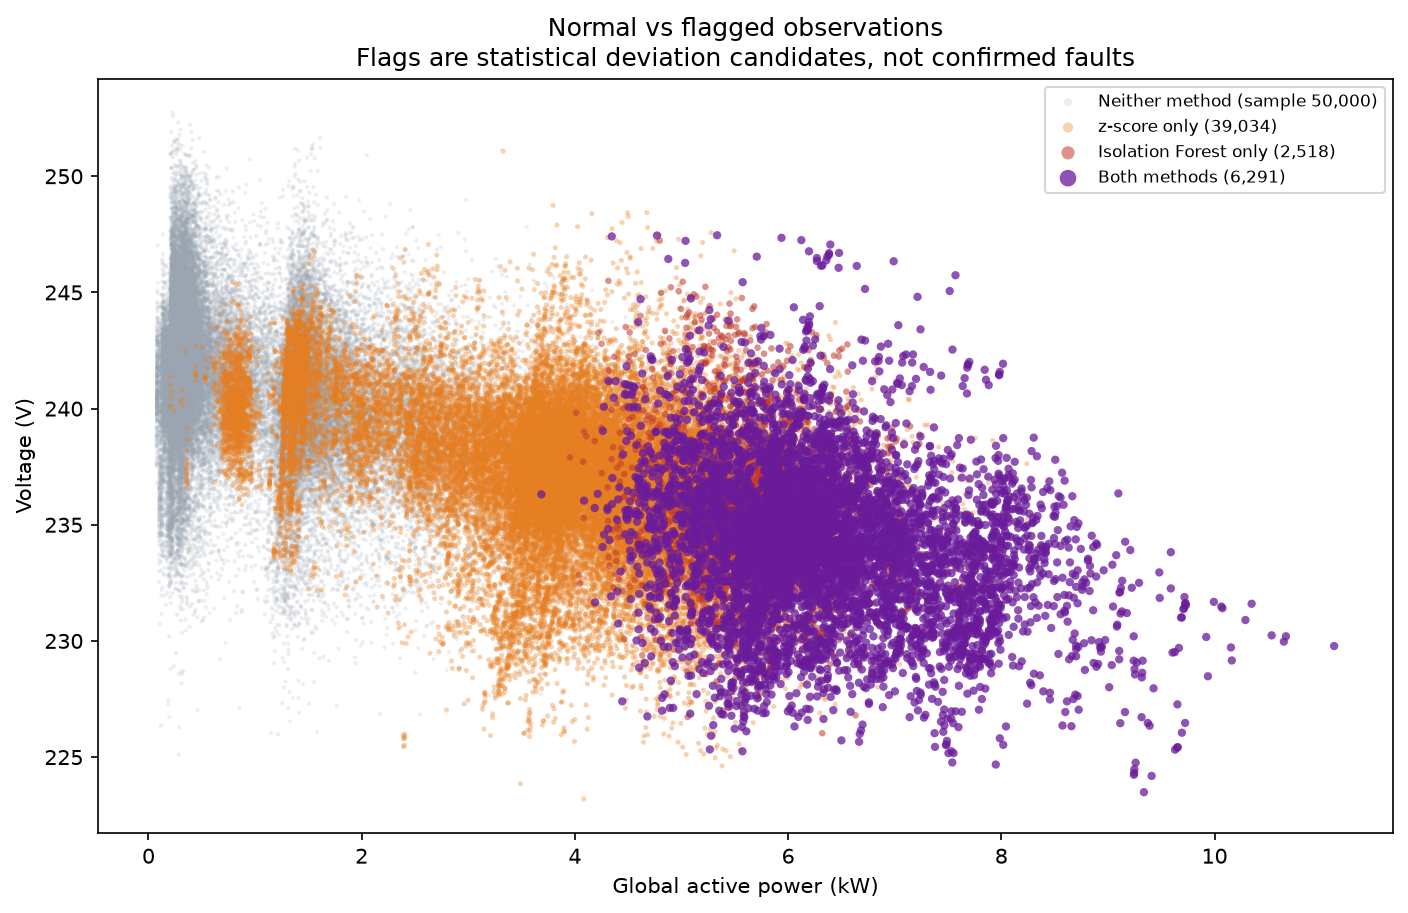

In [8]:
anomaly_figures = [
    "anomaly_consumption_timeline.png",
    "anomaly_distribution_over_time.png",
    "anomaly_score_distribution.png",
    "anomaly_method_comparison.png",
    "anomaly_hourly_profile.png",
    "anomaly_normal_vs_anomalous.png",
]
for filename in anomaly_figures:
    path = FIGURE_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing anomaly figure: {path}")
    display(Markdown(f"**{filename}**"))
    display(Image(filename=str(path), width=1100))

## 12. Findings and Limitations

**What the experiment shows**

- Both methods surface a small fraction of candidate minutes, but they answer
  different questions: the z-score detects local univariate excursions, while
  the Isolation Forest detects multivariate isolation.
- Agreement is partial and is reported as Jaccard overlap, not accuracy.
- Detection rates vary across splits because household behaviour changes over
  four years and because the Isolation Forest threshold is learned from the
  training period.
- The saved scaler and forest reproduce stored flags exactly on a real test
  sample.

**Limitations**

- No reliable ground-truth labels exist, so accuracy, precision, recall and F1
  are intentionally absent.
- Detected observations are deviation candidates, not confirmed faults.
- The 0.5% contamination is an assumption, not an estimated prevalence.
- The rolling z-score assumes approximate local stability and is sensitive to
  autocorrelation and heavy tails; 3.0 is a convention, not a calibrated
  probability.
- Interpolated minutes and rows without full history are excluded; long missing
  intervals are absent, so gap-adjacent behaviour is under-represented.
- No weather, occupancy, appliance identity, maintenance or tariff context is
  available. Scores describe statistical deviation, not physical causation.

## 13. Notebook Verification Checklist

The final cell verifies the saved artefacts and the honesty constraints of the
notebook.

In [9]:
checklist = pd.DataFrame(
    [
        {"check": "Prediction rows equal usable minutes", "passed": len(predictions) == source["usable_minutes"]},
        {"check": "Timestamps are unique and chronological", "passed": bool(predictions["timestamp"].is_monotonic_increasing and not predictions["timestamp"].duplicated().any())},
        {"check": "Detection counts reconcile with the summary CSV", "passed": int(counts["detected_anomalies"].sum()) == int(iforest.sum() + zscore.sum())},
        {"check": "Reloaded Isolation Forest reproduces stored flags", "passed": iforest_mismatches == 0},
        {"check": "Rolling z-score flags recompute exactly", "passed": z_mismatches == 0},
        {"check": "No supervised anomaly metric is reported", "passed": not any(column in predictions.columns for column in ("accuracy", "precision", "recall", "f1"))},
    ]
)
display(checklist)
assert checklist["passed"].all()
print("All notebook checks passed. Unsupervised results are not presented as labelled accuracy.")

,check,passed
0,Prediction rows equal usable minutes,True
1,Timestamps are unique and chronological,True
2,Detection counts reconcile with the summary CSV,True
3,Reloaded Isolation Forest reproduces stored flags,True
4,Rolling z-score flags recompute exactly,True
5,No supervised anomaly metric is reported,True


All notebook checks passed. Unsupervised results are not presented as labelled accuracy.
